# MSCS 634 – Project Deliverable 1
## Data Collection, Cleaning, and Exploration
### Dataset: IBM Telco Customer Churn

**Course:** MSCS 634
**Authors:** Pranavi Balakulla, Sandeep Reddy Banda, Sowmya Cheruku, Vineela Reddy Karnatakam
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling

---

**Notebook roadmap**

1. Dataset selection and justification
2. Environment setup
3. Loading and inspecting the data
4. Data-quality assessment (what is wrong with the raw data?)
5. Data cleaning (missing values, duplicates, inconsistent data, noisy data)
6. Exploratory data analysis (distributions, outliers, relationships)
7. Key insights and how they guide Deliverables 2–4
8. Challenges and how they were addressed

## 1. Dataset Selection and Justification

### 1.1 Description

The **Telco Customer Churn** dataset was published by IBM as a sample dataset and is mirrored on Kaggle
(`blastchar/telco-customer-churn`) and on IBM's public GitHub. It describes **7,043 customers** of a fictional
telecommunications company that sells home phone and internet services. Each row is one customer; each column
describes the customer's demographics, the services they subscribe to, their account and billing details, and whether
they **churned** (left the company) in the last month.

| # | Attribute | Type | Description |
|---|-----------|------|-------------|
| 1 | `customerID` | ID | Unique customer identifier |
| 2 | `gender` | Categorical | Male / Female |
| 3 | `SeniorCitizen` | Binary (0/1) | 1 if the customer is a senior citizen |
| 4 | `Partner` | Categorical | Has a partner (Yes/No) |
| 5 | `Dependents` | Categorical | Has dependents (Yes/No) |
| 6 | `tenure` | Numeric | Months the customer has stayed with the company (0–72) |
| 7 | `PhoneService` | Categorical | Has phone service (Yes/No) |
| 8 | `MultipleLines` | Categorical | Yes / No / No phone service |
| 9 | `InternetService` | Categorical | DSL / Fiber optic / No |
| 10–15 | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Categorical | Add-on services: Yes / No / No internet service |
| 16 | `Contract` | Categorical | Month-to-month / One year / Two year |
| 17 | `PaperlessBilling` | Categorical | Yes / No |
| 18 | `PaymentMethod` | Categorical | Electronic check / Mailed check / Bank transfer (automatic) / Credit card (automatic) |
| 19 | `MonthlyCharges` | Numeric | Current monthly bill (USD) |
| 20 | `TotalCharges` | Numeric (stored as text!) | Total amount billed over the customer's lifetime (USD) |
| 21 | `Churn` | Categorical – **target** | Did the customer leave in the last month? (Yes/No) |

### 1.2 Why this dataset fits the whole project

| Requirement | How the dataset meets it |
|---|---|
| ≥ 500 records, 8–10+ attributes | **7,043 records** and **21 attributes** (19 features + ID + target) |
| Realistic cleaning work (Deliverable 1) | Hidden blank values, a numeric column stored as text, inconsistent encodings (`0/1` vs `Yes/No`), redundant categories (`No internet service`), and duplicate-looking profiles |
| **Regression** (Deliverable 2) | Continuous targets are available: `MonthlyCharges` (driven by the service mix) and `TotalCharges` |
| **Classification** (Deliverable 3) | A clear, business-relevant binary target: `Churn` |
| **Clustering** (Deliverable 3) | Customers can be segmented by tenure, spend, and service usage |
| **Association rules** (Deliverable 4) | Most attributes are Yes/No service flags, which map naturally to "items" in a transaction (e.g. *{Month-to-month, Fiber optic} ⇒ {Churn = Yes}*) |
| Practical value | Keeping an existing customer is usually far cheaper than acquiring a new one, so knowing *who* churns and *why* has direct business value |

Because every later deliverable needs a different kind of target (continuous, binary, none, and itemsets),
choosing a dataset that supports **all four** techniques was the most important decision of the project.

## 2. Environment Setup

We use **Pandas/NumPy** for data handling, **Matplotlib/Seaborn** for visualization, and **SciPy** for the
statistical tests used to measure feature–target association.

In [1]:
# ---------------------------------------------------------------
# Core libraries
# ---------------------------------------------------------------
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy.stats import chi2_contingency, pointbiserialr

warnings.filterwarnings("ignore")          # keep the notebook output readable
pd.set_option("display.max_columns", 50)    # show every column when printing a DataFrame
pd.set_option("display.width", 140)

# Folder for exported figures (the README embeds some of them)
FIG_DIR = "Images"
os.makedirs(FIG_DIR, exist_ok=True)

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 2.2.3 | seaborn 0.13.2


In [2]:
# ---------------------------------------------------------------
# Consistent, colour-blind-safe chart styling
# ---------------------------------------------------------------
# One colour meaning is used in EVERY figure that shows churn status:
#   blue   = customer stayed  (Churn = "No")
#   orange = customer left    (Churn = "Yes")
# Blue/orange remains distinguishable for the common forms of colour blindness.
STAY, LEAVE = "#2a78d6", "#eb6834"
CHURN_COLORS = {"No": STAY, "Yes": LEAVE}

# Neutral inks, grid and background colours
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"

# Sequential (one hue, light -> dark) for magnitudes such as churn rate,
# diverging (blue <-> grey <-> red) for correlations that can be negative or positive.
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list(
    "diverging", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def save(fig, name):
    # Save a figure into Images/ so it can be referenced from the README.
    fig.savefig(os.path.join(FIG_DIR, name))

## 3. Loading and Inspecting the Data

The CSV is stored in the root of the repository. If the file is not found (for example when the notebook is
opened somewhere else), it falls back to IBM's public copy of the same file on GitHub.

In [3]:
# ---------------------------------------------------------------
# 3.1 Load the raw dataset
# ---------------------------------------------------------------
DATA_PATH = "Telco-Customer-Churn.csv"
DATA_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
            "master/data/Telco-Customer-Churn.csv")

source = DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL
raw = pd.read_csv(source)

# Work on a copy so the untouched raw data stays available for before/after comparisons
df = raw.copy()

print(f"Loaded from: {source}")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Loaded from: Telco-Customer-Churn.csv
Rows: 7,043   Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# ---------------------------------------------------------------
# 3.2 Structure: column types and non-null counts
# ---------------------------------------------------------------
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
# ---------------------------------------------------------------
# 3.3 Column profile: data type, number of distinct values, and example values
# ---------------------------------------------------------------
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "example_values": [", ".join(map(str, df[c].unique()[:4])) for c in df.columns],
})
profile

,dtype,n_unique,example_values
customerID,object,7043,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW"
gender,object,2,"Female, Male"
SeniorCitizen,int64,2,"0, 1"
Partner,object,2,"Yes, No"
Dependents,object,2,"No, Yes"
tenure,int64,73,"1, 34, 2, 45"
PhoneService,object,2,"No, Yes"
MultipleLines,object,3,"No phone service, No, Yes"
InternetService,object,3,"DSL, Fiber optic, No"
OnlineSecurity,object,3,"No, Yes, No internet service"


In [6]:
# ---------------------------------------------------------------
# 3.4 Summary statistics for the columns pandas recognises as numeric
# ---------------------------------------------------------------
# NOTE: TotalCharges is missing from this table because it was read as text,
# which is the first sign of a data-quality problem (handled in Section 5).
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


## 4. Data-Quality Assessment

Before changing anything, we measure what is wrong with the raw data. Each issue found here is fixed in Section 5.

In [7]:
# ---------------------------------------------------------------
# 4.1 Standard missing values (NaN)
# ---------------------------------------------------------------
print("NaN values per column (non-zero only):")
nan_counts = df.isna().sum()
print(nan_counts[nan_counts > 0] if nan_counts.sum() else "  none - but see the hidden blanks below")

NaN values per column (non-zero only):
  none - but see the hidden blanks below


In [8]:
# ---------------------------------------------------------------
# 4.2 Hidden missing values: cells that contain only spaces
# ---------------------------------------------------------------
# pandas does not treat " " as missing, so isna() reports 0 even when values are absent.
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
blank_counts = pd.Series({c: int(df[c].astype(str).str.strip().eq("").sum()) for c in text_cols})
print("Whitespace-only cells per column (non-zero only):")
print(blank_counts[blank_counts > 0])

# Confirm the type problem: TotalCharges should be numeric but cannot be parsed as-is
print("\nTotalCharges dtype:", df["TotalCharges"].dtype)
print("Values that fail numeric conversion:",
      pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum())

Whitespace-only cells per column (non-zero only):
TotalCharges    11
dtype: int64

TotalCharges dtype: object
Values that fail numeric conversion: 11


In [9]:
# ---------------------------------------------------------------
# 4.3 Duplicates
# ---------------------------------------------------------------
print("Duplicate customerIDs           :", df["customerID"].duplicated().sum())
print("Fully duplicated rows           :", df.duplicated().sum())
print("Duplicates ignoring customerID  :", df.drop(columns="customerID").duplicated().sum())

Duplicate customerIDs           : 0
Fully duplicated rows           : 0
Duplicates ignoring customerID  : 22


In [10]:
# ---------------------------------------------------------------
# 4.4 Inconsistent encodings and redundant categories
# ---------------------------------------------------------------
# (a) SeniorCitizen uses 0/1 while every other yes/no column uses "Yes"/"No"
print("SeniorCitizen values:", sorted(df["SeniorCitizen"].unique()))

# (b) Six add-on columns have a third level, "No internet service", and MultipleLines has
#     "No phone service". Check that these levels are LOGICALLY consistent with the parent column:
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
no_internet = df["InternetService"].eq("No")
for c in addon_cols:
    level = df[c].eq("No internet service")
    print(f"{c:<17} 'No internet service' rows: {level.sum():>5} | "
          f"matches InternetService=='No' exactly: {(level == no_internet).all()}")

level = df["MultipleLines"].eq("No phone service")
print(f"{'MultipleLines':<17} 'No phone service'    rows: {level.sum():>5} | "
      f"matches PhoneService=='No' exactly: {(level == df['PhoneService'].eq('No')).all()}")

SeniorCitizen values: [np.int64(0), np.int64(1)]
OnlineSecurity    'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
OnlineBackup      'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
DeviceProtection  'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
TechSupport       'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
StreamingTV       'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
StreamingMovies   'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
MultipleLines     'No phone service'    rows:   682 | matches PhoneService=='No' exactly: True


**Findings from the assessment**

| Issue | Where | Scale |
|---|---|---|
| Hidden missing values (single space) | `TotalCharges` | 11 rows |
| Numeric column stored as text | `TotalCharges` | whole column |
| Inconsistent encoding (`0/1` vs `Yes/No`) | `SeniorCitizen` | whole column |
| Redundant category levels | 6 add-on columns + `MultipleLines` | 1,526 / 682 rows |
| Identical profiles under different IDs | all columns except `customerID` | 22 rows |

The redundant levels are perfectly consistent with `InternetService` / `PhoneService`, so they repeat information
that already exists in another column. That makes it safe to merge them into `"No"` (Section 5.4).

## 5. Data Cleaning

### 5.1 Trim whitespace and convert `TotalCharges` to a number

In [11]:
# ---------------------------------------------------------------
# 5.1 Strip leading/trailing spaces from every text column
# ---------------------------------------------------------------
# This turns the " " cells into true empty strings and protects against
# categories such as "Yes " vs "Yes" being counted as different values.
for c in text_cols:
    df[c] = df[c].str.strip()

# Convert TotalCharges to float; empty strings become NaN (a real, detectable missing value)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace("", np.nan), errors="coerce")
missing_mask = df["TotalCharges"].isna()

print("TotalCharges dtype now:", df["TotalCharges"].dtype)
print("Missing TotalCharges  :", missing_mask.sum())
df.loc[missing_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

TotalCharges dtype now: float64
Missing TotalCharges  : 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


### 5.2 Handle missing values

All 11 missing `TotalCharges` rows share one pattern: **`tenure = 0`**. These are brand-new customers who signed
a contract but have not been billed yet. That tells us the value is not *unknown* — it is **zero**.

Options considered:

| Option | Result | Decision |
|---|---|---|
| Drop the 11 rows | Loses valid customers (0.16% of data); removes the "brand-new customer" group entirely | Rejected |
| Mean/median imputation | Would give a customer with 0 months of service a lifetime bill of over \$1,000 — logically impossible | Rejected |
| **Domain-based imputation: 0** | Consistent with `TotalCharges ≈ tenure × MonthlyCharges` (0 × anything = 0) | **Chosen** |

In [12]:
# ---------------------------------------------------------------
# 5.2 Domain-based imputation of TotalCharges
# ---------------------------------------------------------------
# Every missing row has tenure == 0, so the correct lifetime bill is 0
assert (df.loc[missing_mask, "tenure"] == 0).all(), "Unexpected: missing TotalCharges with tenure > 0"

# Show why median imputation would be wrong
print(f"Median TotalCharges (what median imputation would insert): ${df['TotalCharges'].median():,.2f}")

df.loc[missing_mask, "TotalCharges"] = 0.0
print("Missing values remaining in the whole dataset:", int(df.isna().sum().sum()))

Median TotalCharges (what median imputation would insert): $1,397.47
Missing values remaining in the whole dataset: 0


### 5.3 Duplicates

There are no duplicate `customerID`s and no fully duplicated rows. However, **22 rows** become identical once
the ID is ignored. Before deleting anything, we look at what those rows are.

In [13]:
# ---------------------------------------------------------------
# 5.3 Inspect rows that are identical apart from customerID
# ---------------------------------------------------------------
feature_cols = [c for c in df.columns if c != "customerID"]
dup_mask = df.duplicated(subset=feature_cols, keep=False)    # keep=False marks every copy

dups = df[dup_mask]
print(f"Rows involved in duplicate profiles: {dup_mask.sum()}  (extra copies: {df.duplicated(subset=feature_cols).sum()})")
print("Tenure values among them :", sorted(dups["tenure"].unique()))
print("Internet service         :", dups["InternetService"].value_counts().to_dict())
print("Contract                 :", dups["Contract"].value_counts().to_dict())
dups.sort_values(["MonthlyCharges"]).head(6)[["customerID", "tenure", "PhoneService", "InternetService",
                                              "Contract", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows involved in duplicate profiles: 42  (extra copies: 22)
Tenure values among them : [np.int64(1)]
Internet service         : {'No': 26, 'Fiber optic': 12, 'DSL': 4}
Contract                 : {'Month-to-month': 42}


,customerID,tenure,PhoneService,InternetService,Contract,MonthlyCharges,TotalCharges,Churn
542,2866-IKBTM,1,Yes,No,Month-to-month,19.55,19.55,No
1491,8605-ITULD,1,Yes,No,Month-to-month,19.55,19.55,No
5170,7721-DVEKZ,1,Yes,No,Month-to-month,19.65,19.65,No
6774,0970-QXPXW,1,Yes,No,Month-to-month,19.65,19.65,No
6706,7878-RTCZG,1,Yes,No,Month-to-month,19.90,19.90,No
4817,6654-QGBZZ,1,Yes,No,Month-to-month,19.90,19.90,No


**Decision: keep them.** All 42 rows involved are **first-month (`tenure = 1`), month-to-month customers on the
simplest plans** — 26 have phone service only and 16 have internet only, none with any add-ons. With so few attributes
able to vary (and the bill equal to one month's charge), different people on the same basic plan will naturally look
identical. They have **different customer IDs** and mixed churn outcomes, so they are separate customers, not
data-entry repeats. Removing them would under-represent the company's newest, most basic customer segment.

### 5.4 Fix inconsistent data

In [14]:
# ---------------------------------------------------------------
# 5.4a Make SeniorCitizen use the same Yes/No coding as every other binary column
# ---------------------------------------------------------------
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# ---------------------------------------------------------------
# 5.4b Merge redundant levels into "No"
# ---------------------------------------------------------------
# "No internet service" is exactly the same information as InternetService == "No" (verified in 4.4),
# and "No phone service" is exactly PhoneService == "No". Merging leaves every add-on column as a
# clean Yes/No flag (easier to encode and to use as association-rule items) WITHOUT losing information,
# because InternetService and PhoneService still record who has no service.
for c in addon_cols:
    df[c] = df[c].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

# ---------------------------------------------------------------
# 5.4c Validate that every categorical column now holds only the expected values
# ---------------------------------------------------------------
yes_no = {"Yes", "No"}
expected = {
    "gender": {"Male", "Female"},
    "InternetService": {"DSL", "Fiber optic", "No"},
    "Contract": {"Month-to-month", "One year", "Two year"},
    "PaymentMethod": {"Electronic check", "Mailed check",
                      "Bank transfer (automatic)", "Credit card (automatic)"},
}
for c in ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
          "PaperlessBilling", "Churn"] + addon_cols:
    expected[c] = yes_no

problems = {c: set(df[c].unique()) - allowed for c, allowed in expected.items()
            if set(df[c].unique()) - allowed}
print("Unexpected category values:", problems if problems else "none - all columns valid")

Unexpected category values: none - all columns valid


### 5.5 Identify and address noisy data

"Noise" means values that are random errors or extreme deviations. We check for it in three ways:

1. **Statistical outliers** in the numeric columns (IQR rule and z-scores).
2. **Logical/domain rules** that must hold for valid records.
3. **Cross-field consistency**: `TotalCharges` should be roughly `tenure × MonthlyCharges`.

In [15]:
# ---------------------------------------------------------------
# 5.5a Statistical outlier detection
# ---------------------------------------------------------------
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr                    # Tukey fences
    z = (df[c] - df[c].mean()) / df[c].std()                   # standard score
    rows.append({
        "column": c, "min": df[c].min(), "max": df[c].max(),
        "lower_fence": round(lo, 2), "upper_fence": round(hi, 2),
        "IQR_outliers": int(((df[c] < lo) | (df[c] > hi)).sum()),
        "|z|>3_outliers": int((z.abs() > 3).sum()),
        "skewness": round(df[c].skew(), 3),
    })
pd.DataFrame(rows).set_index("column")

,min,max,lower_fence,upper_fence,IQR_outliers,|z|>3_outliers,skewness
column,,,,,,,
tenure,0.00,72.00,-60.00,124.00,0,0,0.240
MonthlyCharges,18.25,118.75,-46.02,171.38,0,0,-0.221
TotalCharges,0.00,8684.80,-4683.52,8868.67,0,0,0.963


In [16]:
# ---------------------------------------------------------------
# 5.5b Domain-rule checks (each should report 0 violations)
# ---------------------------------------------------------------
rules = {
    "tenure outside 0-72 months":                      ~df["tenure"].between(0, 72),
    "MonthlyCharges <= 0":                              df["MonthlyCharges"] <= 0,
    "TotalCharges < 0":                                 df["TotalCharges"] < 0,
    "tenure > 0 but TotalCharges == 0":                (df["tenure"] > 0) & (df["TotalCharges"] == 0),
    "no phone AND no internet (no service at all)":    df["PhoneService"].eq("No") & df["InternetService"].eq("No"),
    "add-on service but no internet":                  df["InternetService"].eq("No") & df[addon_cols].eq("Yes").any(axis=1),
    "multiple lines but no phone service":             df["PhoneService"].eq("No") & df["MultipleLines"].eq("Yes"),
}
pd.Series({k: int(v.sum()) for k, v in rules.items()}, name="violations").to_frame()

,violations
tenure outside 0-72 months,0
MonthlyCharges <= 0,0
TotalCharges < 0,0
tenure > 0 but TotalCharges == 0,0
no phone AND no internet (no service at all),0
add-on service but no internet,0
multiple lines but no phone service,0


In [17]:
# ---------------------------------------------------------------
# 5.5c Cross-field consistency: TotalCharges vs tenure x MonthlyCharges
# ---------------------------------------------------------------
billed = df["tenure"] * df["MonthlyCharges"]                                  # expected lifetime bill
ratio = np.where(billed > 0, df["TotalCharges"] / billed, 1.0)              # 1.0 = perfectly consistent
df_ratio = pd.Series(ratio, index=df.index)

print(df_ratio.describe().round(3))
inconsistent = (df_ratio - 1).abs() > 0.25
print(f"\nCustomers whose TotalCharges differs from tenure x MonthlyCharges by more than 25%: {inconsistent.sum()}")
print("Median tenure of those customers:", df.loc[inconsistent, "tenure"].median(), "months")

count    7043.000
mean        1.000
std         0.051
min         0.689
25%         0.980
50%         1.000
75%         1.019
max         1.573
dtype: float64

Customers whose TotalCharges differs from tenure x MonthlyCharges by more than 25%: 27
Median tenure of those customers: 3.0 months


**Interpretation and decisions on noise**

* **No statistical outliers.** The IQR rule and the |z| > 3 rule both flag **0** values in all three numeric columns.
  `TotalCharges` is strongly right-skewed (skew ≈ 0.96), but the extreme values are long-tenure customers with
  large bills, i.e. genuine customers. **No rows are removed**; the skew will be handled with a log transform or
  scaling at modeling time.
* **No domain-rule violations.** Every customer has at least one service, and add-ons only appear for customers
  with the matching base service.
* **Small billing inconsistencies are real-world noise, not errors.** For 27 customers the lifetime bill differs from
  `tenure × MonthlyCharges` by more than 25%. They are mostly short-tenure customers, for whom a single price change
  (e.g. adding or dropping a service mid-contract) moves the ratio a lot. Because the overall ratio is centred at
  1.00, these records are **kept unchanged**.
* **Smoothing by binning.** To reduce the effect of small month-to-month variation, `tenure` is also smoothed into
  five **tenure groups**. Binning is a standard noise-smoothing technique and the groups will also be needed as
  discrete items for association-rule mining in Deliverable 4.

### 5.6 Derived columns that support the analysis

Three helper columns are added. They do not change the original attributes; they make the EDA (and later modeling)
easier.

* `Churn_flag` — numeric version of the target (1 = churned) so churn **rates** can be averaged.
* `tenure_group` — binned tenure (smoothing, see 5.5).
* `NumServices` — how many services a customer subscribes to (phone, extra lines, internet, and six add-ons).

In [18]:
# ---------------------------------------------------------------
# 5.6 Derived columns
# ---------------------------------------------------------------
df["Churn_flag"] = df["Churn"].map({"No": 0, "Yes": 1})

# Equal-meaning business bins: first year, second year, years 3-4, year 5, year 6
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 60, 72],
                            labels=["0-12", "13-24", "25-48", "49-60", "61-72"])

service_flags = ["PhoneService", "MultipleLines"] + addon_cols
df["NumServices"] = df[service_flags].eq("Yes").sum(axis=1) + df["InternetService"].ne("No").astype(int)

df[["tenure", "tenure_group", "NumServices", "Churn", "Churn_flag"]].head()

,tenure,tenure_group,NumServices,Churn,Churn_flag
0,1,0-12,2,No,0
1,34,25-48,4,No,0
2,2,0-12,4,Yes,1
3,45,25-48,4,No,0
4,2,0-12,2,Yes,1


### 5.7 Cleaning summary and export

In [19]:
# ---------------------------------------------------------------
# 5.7 Before / after summary
# ---------------------------------------------------------------
summary = pd.DataFrame({
    "Raw data": [
        f"{raw.shape[0]:,} x {raw.shape[1]}",
        int(raw.isna().sum().sum()),
        int(raw["TotalCharges"].astype(str).str.strip().eq("").sum()),
        str(raw["TotalCharges"].dtype),
        ", ".join(map(str, sorted(raw["SeniorCitizen"].unique()))),
        int(raw[addon_cols].eq("No internet service").any(axis=1).sum()),
    ],
    "Cleaned data": [
        f"{df.shape[0]:,} x {df.shape[1]}",
        int(df.isna().sum().sum()),
        int((df["TotalCharges"].astype(str).str.strip() == "").sum()),
        str(df["TotalCharges"].dtype),
        ", ".join(sorted(df["SeniorCitizen"].unique())),
        int(df[addon_cols].eq("No internet service").any(axis=1).sum()),
    ],
}, index=["Shape (rows x cols)", "NaN cells", "Blank TotalCharges", "TotalCharges dtype",
          "SeniorCitizen values", "Rows with 'No internet service'"])
summary

,Raw data,Cleaned data
Shape (rows x cols),"7,043 x 21","7,043 x 24"
NaN cells,0,0
Blank TotalCharges,11,0
TotalCharges dtype,object,float64
SeniorCitizen values,"0, 1","No, Yes"
Rows with 'No internet service',1526,0


In [20]:
# ---------------------------------------------------------------
# Save the cleaned dataset so Deliverables 2-4 start from the same clean data
# ---------------------------------------------------------------
CLEAN_PATH = "telco_churn_cleaned.csv"
df.to_csv(CLEAN_PATH, index=False)
print(f"Saved cleaned data -> {CLEAN_PATH}  ({df.shape[0]:,} rows, {df.shape[1]} columns)")

Saved cleaned data -> telco_churn_cleaned.csv  (7,043 rows, 24 columns)


## 6. Exploratory Data Analysis (EDA)

### 6.1 Target variable: how many customers churn?

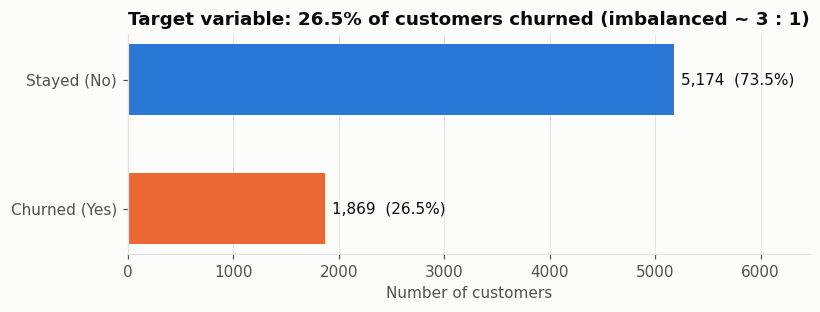

In [21]:
# ---------------------------------------------------------------
# 6.1 Class balance of the target
# ---------------------------------------------------------------
counts = df["Churn"].value_counts().reindex(["No", "Yes"])
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 2.6))
bars = ax.barh(["Stayed (No)", "Churned (Yes)"], counts.values, color=[STAY, LEAVE], height=0.55)
for b, n, p in zip(bars, counts.values, pct.values):
    ax.text(b.get_width() + 70, b.get_y() + b.get_height() / 2, f"{n:,}  ({p:.1f}%)", va="center")
ax.invert_yaxis()
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Number of customers")
ax.grid(axis="y", visible=False)
ax.set_title(f"Target variable: {pct['Yes']:.1f}% of customers churned (imbalanced ~ 3 : 1)")
save(fig, "01_churn_distribution.png")
plt.show()

**Observation.** About **1 in 4** customers churned (1,869 of 7,043). The classes are **imbalanced (≈ 73% / 27%)**,
so a model that always predicts "No" would already be 73% accurate. Accuracy alone will therefore be a misleading
metric in Deliverable 3.

### 6.2 Distributions of the numeric features

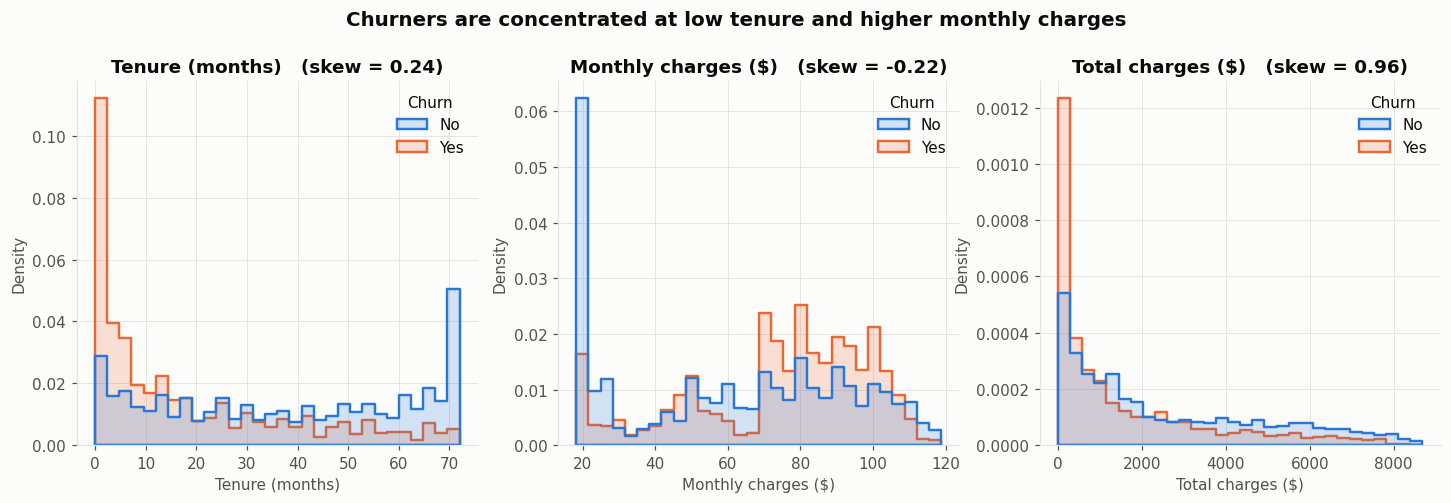

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1679.52
Yes,10.0,79.65,703.55


In [22]:
# ---------------------------------------------------------------
# 6.2 Histograms of each numeric feature, split by churn status
# ---------------------------------------------------------------
# stat="density" + common_norm=False puts both groups on the same scale even though
# there are ~3x more "No" customers, so the SHAPES can be compared directly.
labels = {"tenure": "Tenure (months)", "MonthlyCharges": "Monthly charges ($)",
          "TotalCharges": "Total charges ($)"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", hue_order=["No", "Yes"], palette=CHURN_COLORS,
                 bins=30, stat="density", common_norm=False, element="step",
                 fill=True, alpha=0.2, linewidth=1.6, ax=ax)
    ax.set_title(f"{labels[col]}   (skew = {df[col].skew():.2f})")
    ax.set_xlabel(labels[col])
    ax.set_ylabel("Density")
    ax.get_legend().set_title("Churn")
fig.suptitle("Churners are concentrated at low tenure and higher monthly charges", y=1.03,
             fontsize=13, fontweight="bold")
save(fig, "02_numeric_distributions.png")
plt.show()

# Medians by churn status back up what the plots show
df.groupby("Churn")[num_cols].median().round(2)

**Observations**

* **Tenure** is bimodal: many very new customers and many long-standing (≈ 72-month) customers. Churners are piled up
  in the **first few months** (median tenure 10 months vs 38 for customers who stayed).
* **MonthlyCharges** is not normal — there is a large spike around \$20 (phone-only customers with no internet) and a
  broad hump at \$70–\$105. Churners are concentrated in the **higher-charge** range.
* **TotalCharges** is heavily **right-skewed** (skew ≈ 0.96). Churners have *lower* lifetime totals simply because they
  leave early.

### 6.3 Outlier check with box plots

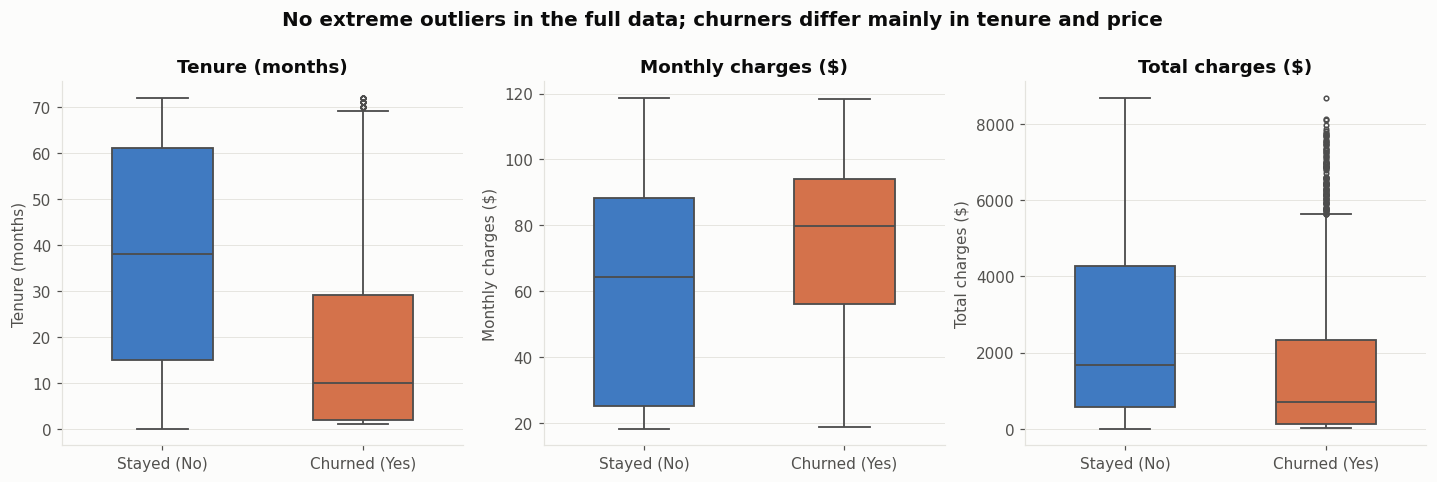

In [23]:
# ---------------------------------------------------------------
# 6.3 Box plots: outliers and the spread of each numeric feature by churn status
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=col, order=["No", "Yes"], hue="Churn", hue_order=["No", "Yes"],
                palette=CHURN_COLORS, legend=False, width=0.5, linewidth=1.2, fliersize=3, ax=ax)
    ax.set_xticks([0, 1], ["Stayed (No)", "Churned (Yes)"])
    ax.set_xlabel("")
    ax.set_ylabel(labels[col])
    ax.set_title(labels[col])
fig.suptitle("No extreme outliers in the full data; churners differ mainly in tenure and price", y=1.03,
             fontsize=13, fontweight="bold")
save(fig, "03_boxplots_outliers.png")
plt.show()

**Observations.** Across the full dataset none of the numeric features has values outside the 1.5 × IQR fences
(confirmed numerically in 5.5a). The few points drawn beyond the whiskers for churners' `tenure` and `TotalCharges`
appear only *within the churn subgroup*, because that group is concentrated at short tenures — they are long-tenure
customers who churned, which is real behaviour, not noise. **No outlier removal is needed.**

### 6.4 Categorical features vs churn rate

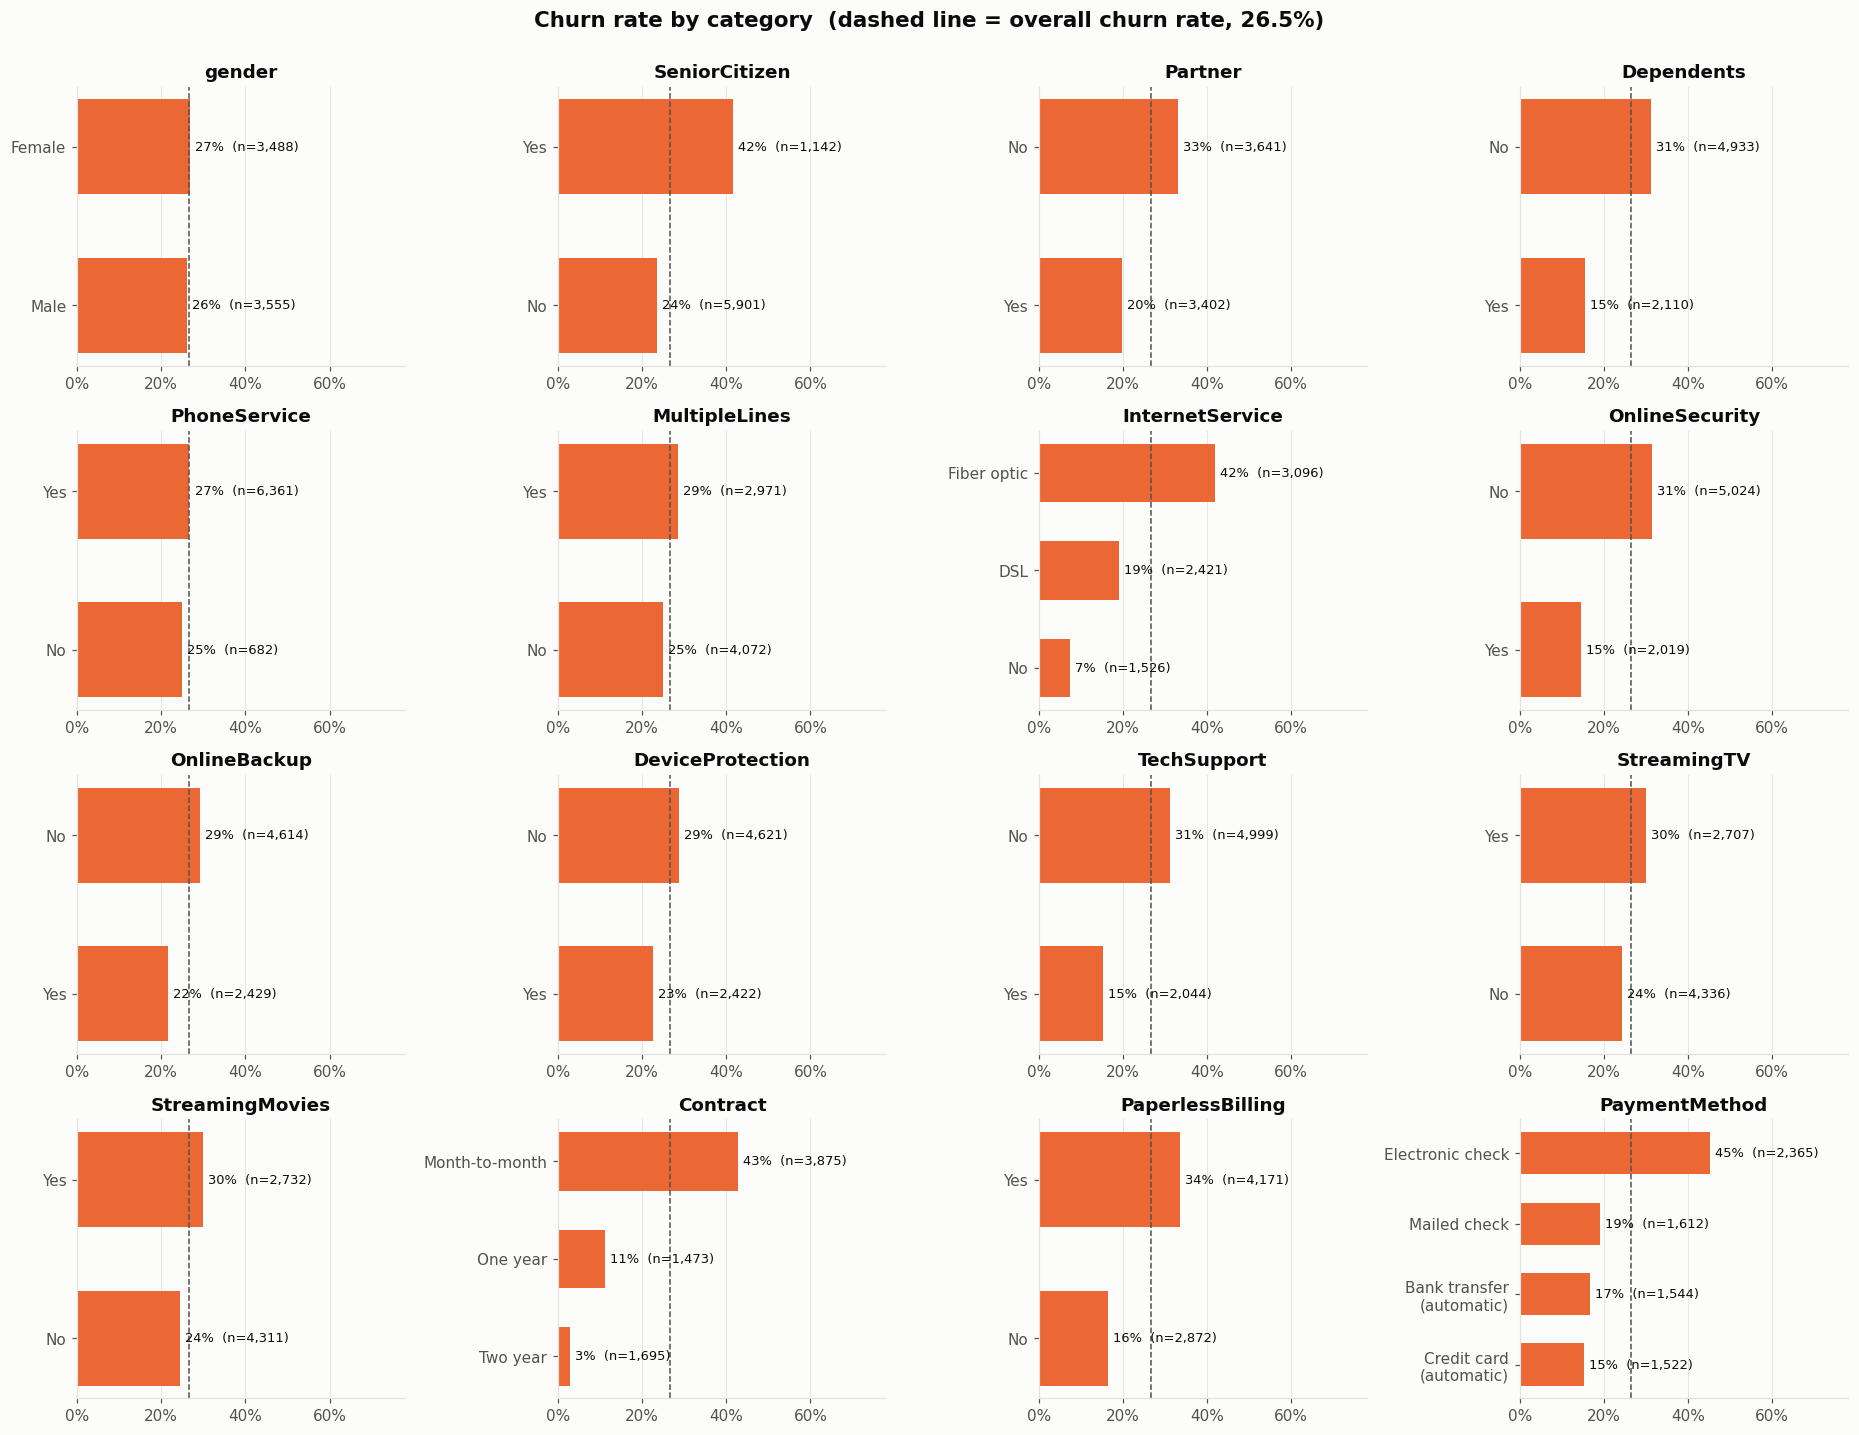

In [24]:
# ---------------------------------------------------------------
# 6.4 Churn rate for every level of every categorical feature
# ---------------------------------------------------------------
cat_features = ["gender", "SeniorCitizen", "Partner", "Dependents",
                "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
                "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
                "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
overall = df["Churn_flag"].mean()

fig, axes = plt.subplots(4, 4, figsize=(17, 13))
for ax, col in zip(axes.flat, cat_features):
    rate = df.groupby(col)["Churn_flag"].agg(["mean", "size"]).sort_values("mean")
    names = [str(i).replace(" (", "\n(") for i in rate.index]          # wrap long labels
    ax.barh(names, rate["mean"], color=LEAVE, height=0.6)
    ax.axvline(overall, color=INK_2, ls="--", lw=1)                     # overall churn rate
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(m + 0.012, i, f"{m:.0%}  (n={n:,})", va="center", fontsize=8.5)
    ax.set_xlim(0, 0.78)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
    ax.set_title(col)
fig.suptitle(f"Churn rate by category  (dashed line = overall churn rate, {overall:.1%})",
             fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "04_churn_rate_by_category.png")
plt.show()

**Observations**

* **Contract** is the strongest single signal: month-to-month customers churn at **≈ 43%**, compared with ≈ 11% on
  one-year and ≈ 3% on two-year contracts.
* **Fiber optic** internet customers churn at **≈ 42%** — about twice the DSL rate (19%) despite being the premium
  product, which hints at a price or service-quality problem.
* **Electronic check** payers churn at **≈ 45%**, versus 15–19% for every other payment method.
* Customers **without OnlineSecurity or TechSupport** churn about twice as often as those who have them.
* **Senior citizens**, customers **without a partner or dependents**, and **paperless billing** users also churn more.
* **gender** and **PhoneService** show almost no difference from the overall rate — they are weak predictors.

### 6.5 Ranking features by strength of association with churn

Visual comparisons can be misleading, so we quantify association:

* **Cramér's V** (from a chi-square test) for categorical features — 0 = no association, 1 = perfect.
* **Point-biserial correlation** for numeric features vs the binary target.

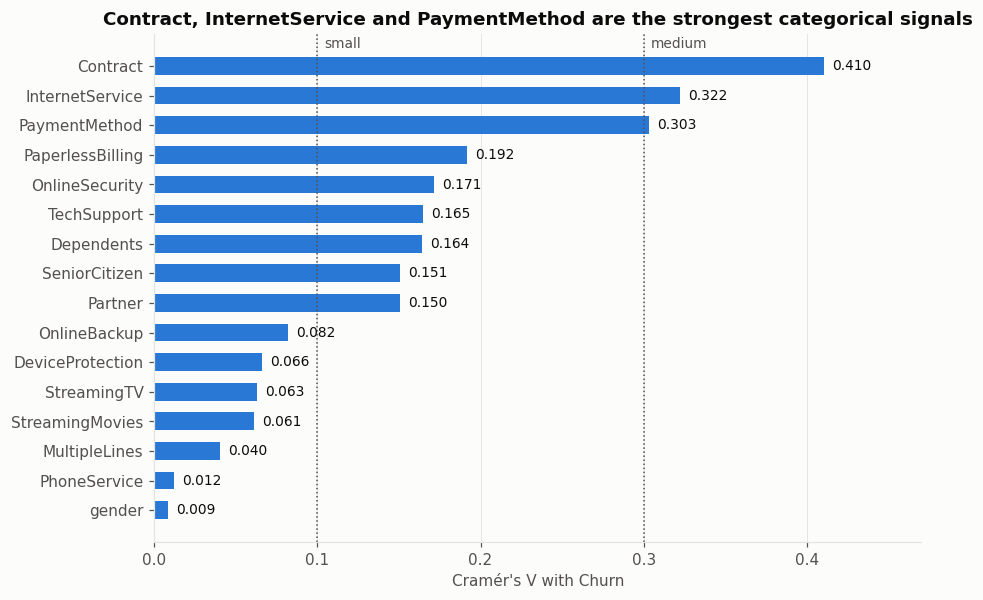

,feature,cramers_v,p_value
0,Contract,0.4101,0.0000
1,InternetService,0.3225,0.0000
2,PaymentMethod,0.3034,0.0000
3,PaperlessBilling,0.1918,0.0000
4,OnlineSecurity,0.1712,0.0000
5,TechSupport,0.1647,0.0000
6,Dependents,0.1642,0.0000
7,SeniorCitizen,0.1509,0.0000
8,Partner,0.1504,0.0000
9,OnlineBackup,0.0823,0.0000


In [25]:
# ---------------------------------------------------------------
# 6.5a Cramer's V for each categorical feature vs Churn
# ---------------------------------------------------------------
def cramers_v(x, y):
    # Cramer's V = sqrt( chi2 / (n * (min(rows, cols) - 1)) )
    table = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(table, correction=False)
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p

assoc = pd.DataFrame([(c, *cramers_v(df[c], df["Churn"])) for c in cat_features],
                     columns=["feature", "cramers_v", "p_value"]).sort_values("cramers_v")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(assoc["feature"], assoc["cramers_v"], color=STAY, height=0.6)
for i, v in enumerate(assoc["cramers_v"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
for x, lab in [(0.1, "small"), (0.3, "medium")]:                     # common effect-size guides
    ax.axvline(x, color=INK_2, ls=":", lw=1)
    ax.text(x + 0.004, len(assoc) - 0.4, lab, color=INK_2, fontsize=9)
ax.set_xlim(0, 0.47)
ax.set_xlabel("Cramér's V with Churn")
ax.grid(axis="y", visible=False)
ax.set_title("Contract, InternetService and PaymentMethod are the strongest categorical signals")
save(fig, "05_cramers_v_ranking.png")
plt.show()

assoc.sort_values("cramers_v", ascending=False).round(4).reset_index(drop=True)

In [26]:
# ---------------------------------------------------------------
# 6.5b Point-biserial correlation for numeric features vs Churn
# ---------------------------------------------------------------
pb = pd.DataFrame([(c, *pointbiserialr(df["Churn_flag"], df[c])) for c in num_cols + ["NumServices"]],
                  columns=["feature", "r_pb", "p_value"])
pb["r_pb"] = pb["r_pb"].round(3)
pb

,feature,r_pb,p_value
0,tenure,-0.352,7.999058e-205
1,MonthlyCharges,0.193,2.706646e-60
2,TotalCharges,-0.198,2.127212e-63
3,NumServices,-0.019,1.039819e-01


**Observations.** `Contract` (V ≈ 0.41), `InternetService` (≈ 0.32) and `PaymentMethod` (≈ 0.30) have the strongest
categorical associations; `tenure` is the strongest numeric one (r ≈ −0.35: longer tenure → less churn).
`gender` (V ≈ 0.009, p ≈ 0.47) and `PhoneService` (V ≈ 0.012, p ≈ 0.32) are **not statistically significant** and are
candidates to drop from the classification model. `NumServices` has almost no *linear* correlation with churn
(r ≈ −0.02) even though Section 6.7c shows a strong pattern — the relationship is **non-linear** (it rises, then falls),
a reminder that correlation coefficients can miss real effects.

### 6.6 Correlation between features (multicollinearity check)

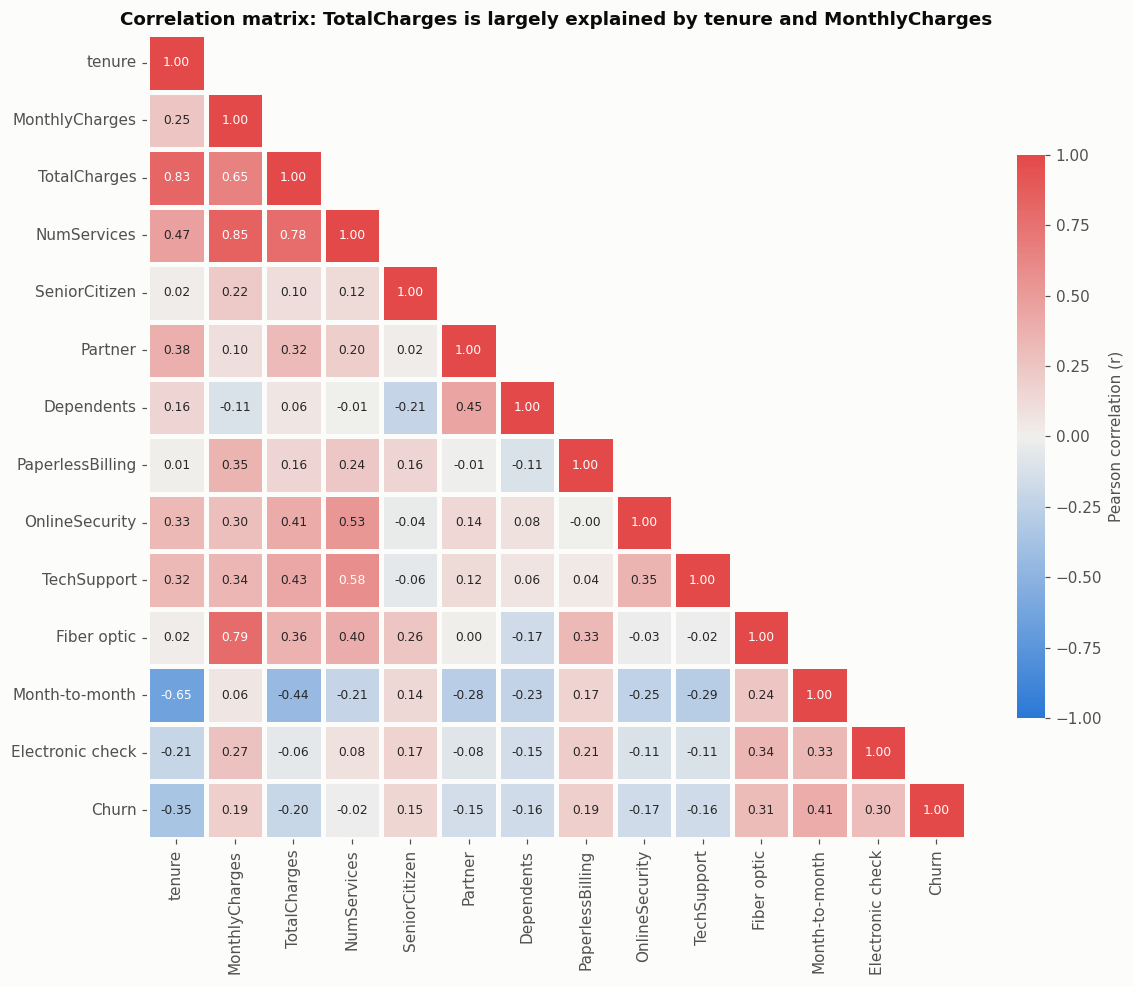

,feature_1,feature_2,r
0,MonthlyCharges,NumServices,0.851
1,TotalCharges,tenure,0.826
2,Fiber optic,MonthlyCharges,0.787
3,NumServices,TotalCharges,0.776
4,MonthlyCharges,TotalCharges,0.651
5,Month-to-month,tenure,-0.646
6,NumServices,TechSupport,0.581
7,NumServices,OnlineSecurity,0.525


In [27]:
# ---------------------------------------------------------------
# 6.6 Correlation heatmap of numeric + key binary-encoded features
# ---------------------------------------------------------------
yn = lambda s: s.eq("Yes").astype(int)          # Yes/No -> 1/0
enc = pd.DataFrame({
    "tenure": df["tenure"], "MonthlyCharges": df["MonthlyCharges"],
    "TotalCharges": df["TotalCharges"], "NumServices": df["NumServices"],
    "SeniorCitizen": yn(df["SeniorCitizen"]), "Partner": yn(df["Partner"]),
    "Dependents": yn(df["Dependents"]), "PaperlessBilling": yn(df["PaperlessBilling"]),
    "OnlineSecurity": yn(df["OnlineSecurity"]), "TechSupport": yn(df["TechSupport"]),
    "Fiber optic": df["InternetService"].eq("Fiber optic").astype(int),
    "Month-to-month": df["Contract"].eq("Month-to-month").astype(int),
    "Electronic check": df["PaymentMethod"].eq("Electronic check").astype(int),
    "Churn": df["Churn_flag"],
})
corr = enc.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)       # hide the redundant upper triangle

fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=2, linecolor=SURFACE,
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation (r)"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation matrix: TotalCharges is largely explained by tenure and MonthlyCharges")
save(fig, "06_correlation_heatmap.png")
plt.show()

# The strongest pairwise correlations (excluding the diagonal)
pairs = (corr.where(~np.eye(len(corr), dtype=bool)).stack()
         .reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "r"}))
pairs = pairs[pairs["feature_1"] < pairs["feature_2"]]
pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).head(8).round(3).reset_index(drop=True)

**Observations**

* `TotalCharges` is strongly correlated with `tenure` (**r ≈ 0.83**) and with `MonthlyCharges` (**r ≈ 0.65**), because it
  is approximately their product. Using all three together in a linear model would cause **multicollinearity**.
* `NumServices` is the strongest predictor of `MonthlyCharges` (**r ≈ 0.85**), followed by `Fiber optic` (**r ≈ 0.79**) —
  more services and a faster connection mean a higher bill.
* `Month-to-month` is strongly negatively correlated with `tenure`: short-tenure customers are on flexible contracts.
* The features most positively correlated with churn are `Month-to-month`, `Fiber optic` and `Electronic check`;
  the most negative are `tenure` and `TotalCharges`.

### 6.7 Feature relationships

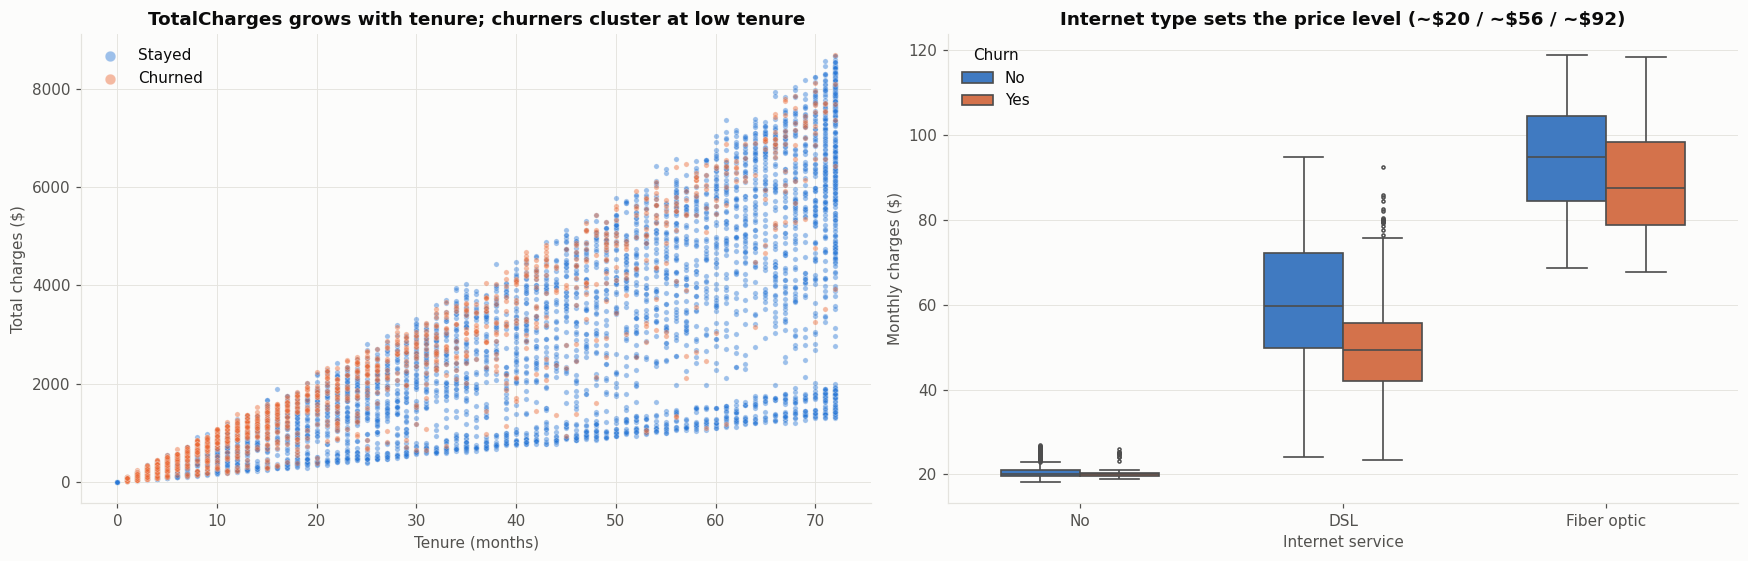

InternetService
DSL            56.15
Fiber optic    91.68
No             20.15
Name: MonthlyCharges, dtype: float64

In [28]:
# ---------------------------------------------------------------
# 6.7a Tenure vs TotalCharges, and MonthlyCharges by internet type
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

ax = axes[0]
for status in ["No", "Yes"]:                    # draw churners last so they sit on top
    sub = df[df["Churn"] == status]
    ax.scatter(sub["tenure"], sub["TotalCharges"], s=12, alpha=0.45, color=CHURN_COLORS[status],
               edgecolor=SURFACE, linewidth=0.3, label="Churned" if status == "Yes" else "Stayed")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Total charges ($)")
ax.set_title("TotalCharges grows with tenure; churners cluster at low tenure")
ax.legend(markerscale=2)

ax = axes[1]
sns.boxplot(data=df, x="InternetService", y="MonthlyCharges", hue="Churn", hue_order=["No", "Yes"],
            order=["No", "DSL", "Fiber optic"], palette=CHURN_COLORS, width=0.6, linewidth=1.1,
            fliersize=2, ax=ax)
ax.set_xlabel("Internet service")
ax.set_ylabel("Monthly charges ($)")
ax.set_title("Internet type sets the price level (~$20 / ~$56 / ~$92)")
ax.legend(title="Churn")

fig.tight_layout()
save(fig, "07_feature_relationships.png")
plt.show()

df.groupby("InternetService")["MonthlyCharges"].median().round(2)

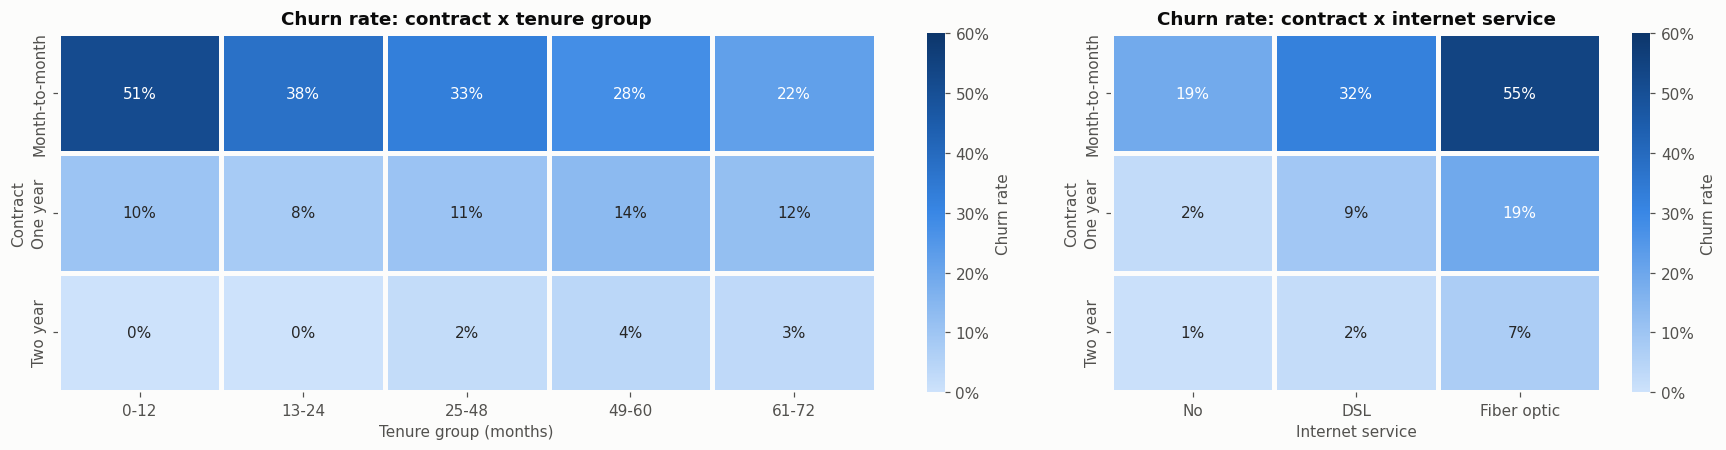

In [29]:
# ---------------------------------------------------------------
# 6.7b Interaction heatmaps: churn rate for combinations of two features
# ---------------------------------------------------------------
contract_order = ["Month-to-month", "One year", "Two year"]
t1 = df.pivot_table(index="Contract", columns="tenure_group", values="Churn_flag",
                    aggfunc="mean", observed=True).reindex(contract_order)
t2 = df.pivot_table(index="Contract", columns="InternetService", values="Churn_flag",
                    aggfunc="mean", observed=True).reindex(contract_order)[["No", "DSL", "Fiber optic"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [5, 3]})
for ax, tbl, xlabel in [(axes[0], t1, "Tenure group (months)"), (axes[1], t2, "Internet service")]:
    sns.heatmap(tbl, cmap=SEQ_BLUE, vmin=0, vmax=0.6, annot=True, fmt=".0%", linewidths=2,
                linecolor=SURFACE, cbar_kws={"label": "Churn rate", "format": mtick.PercentFormatter(1.0)},
                annot_kws={"size": 10}, ax=ax)
    ax.grid(False)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Contract")
axes[0].set_title("Churn rate: contract x tenure group")
axes[1].set_title("Churn rate: contract x internet service")
fig.tight_layout()
save(fig, "08_interaction_heatmaps.png")
plt.show()

**Observations**

* Within **month-to-month** contracts, churn falls steadily with tenure (51% in the first year → 22% after five
  years). On one- and two-year contracts churn stays low at **every** tenure, so the contract itself — not just
  time with the company — is what keeps customers.
* Within each internet type, churners actually pay slightly **less** than customers who stay (6.7a, right panel).
  The overall "churners pay more" pattern is mostly a **mix effect**: churners are concentrated in the expensive
  fiber-optic tier.
* The **month-to-month + fiber optic** combination churns at **≈ 55%**, whereas **two-year + DSL** churns at only
  **≈ 2%**. Effects combine, so models that capture **interactions** (decision trees, random forests) should
  outperform a model that treats features independently.

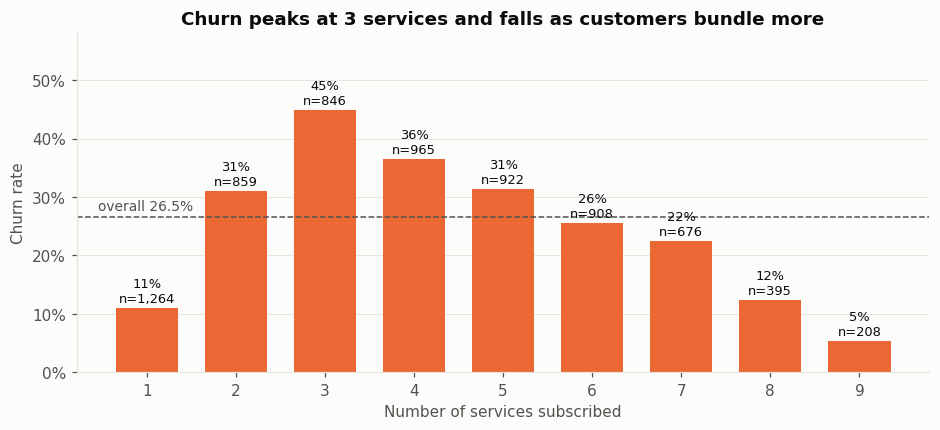

In [30]:
# ---------------------------------------------------------------
# 6.7c Number of services vs churn rate
# ---------------------------------------------------------------
svc = df.groupby("NumServices")["Churn_flag"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(svc.index, svc["mean"], color=LEAVE, width=0.7)
ax.axhline(overall, color=INK_2, ls="--", lw=1)
ax.text(0.45, overall + 0.012, f"overall {overall:.1%}", color=INK_2, fontsize=9, ha="left")
for x, m, n in zip(svc.index, svc["mean"], svc["size"]):
    ax.text(x, m + 0.01, f"{m:.0%}\nn={int(n):,}", ha="center", fontsize=8.5)
ax.set_xticks(svc.index)
ax.set_xlabel("Number of services subscribed")
ax.set_ylabel("Churn rate")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 0.58)
ax.grid(axis="x", visible=False)
ax.set_title("Churn peaks at 3 services and falls as customers bundle more")
save(fig, "09_num_services_churn.png")
plt.show()

**Observations.** Phone-only customers (1 service) rarely churn (≈ 11%). Churn peaks at **3 services (≈ 45%)** —
typically internet plus phone with few protective add-ons — and then falls steadily as customers bundle more services,
reaching ≈ 5% at 9 services. Bundling appears to "lock in" customers, which is a useful pattern to test with
association rules in Deliverable 4.

In [31]:
# ---------------------------------------------------------------
# 6.8 Key numbers quoted in the insights section (computed, not typed by hand)
# ---------------------------------------------------------------
inet = df[df["InternetService"] != "No"]          # customers who could buy add-ons
key = {
    "Churn rate overall": overall,
    "Churn rate - month-to-month": df.loc[df.Contract.eq("Month-to-month"), "Churn_flag"].mean(),
    "Share of all churners on month-to-month": df.loc[df.Churn_flag.eq(1), "Contract"].eq("Month-to-month").mean(),
    "Churn rate - fiber optic": df.loc[df.InternetService.eq("Fiber optic"), "Churn_flag"].mean(),
    "Churn rate - electronic check": df.loc[df.PaymentMethod.eq("Electronic check"), "Churn_flag"].mean(),
    "Churn rate - first 12 months": df.loc[df.tenure_group.eq("0-12"), "Churn_flag"].mean(),
    "Churn rate - 61-72 months": df.loc[df.tenure_group.eq("61-72"), "Churn_flag"].mean(),
    "Internet users WITHOUT TechSupport": inet.loc[inet.TechSupport.eq("No"), "Churn_flag"].mean(),
    "Internet users WITH TechSupport": inet.loc[inet.TechSupport.eq("Yes"), "Churn_flag"].mean(),
    "Internet users WITHOUT OnlineSecurity": inet.loc[inet.OnlineSecurity.eq("No"), "Churn_flag"].mean(),
    "Internet users WITH OnlineSecurity": inet.loc[inet.OnlineSecurity.eq("Yes"), "Churn_flag"].mean(),
    "Churn rate - senior citizens": df.loc[df.SeniorCitizen.eq("Yes"), "Churn_flag"].mean(),
}
pd.Series(key, name="value").map("{:.1%}".format).to_frame()

,value
Churn rate overall,26.5%
Churn rate - month-to-month,42.7%
Share of all churners on month-to-month,88.6%
Churn rate - fiber optic,41.9%
Churn rate - electronic check,45.3%
Churn rate - first 12 months,47.4%
Churn rate - 61-72 months,6.6%
Internet users WITHOUT TechSupport,41.6%
Internet users WITH TechSupport,15.2%
Internet users WITHOUT OnlineSecurity,41.8%


## 7. Key Insights and How They Guide the Next Deliverables

### 7.1 Summary of insights

1. **Churn is imbalanced and substantial.** 26.5% of customers churned (1,869 of 7,043).
2. **Contract type is the #1 driver.** Month-to-month customers churn at 42.7% vs 2.8% on two-year contracts, and they
   account for **88.6% of all churners**.
3. **The first year is the danger zone.** Customers in their first 12 months churn at 47.4%; customers past 5 years
   churn at only 6.6%. Churners have a median tenure of 10 months vs 38 for loyal customers.
4. **Price and product matter.** Churners pay more per month (median \$79.65 vs \$64.43). Fiber-optic customers churn
   at 41.9%, about twice the DSL rate.
5. **Payment behaviour is a signal.** Electronic-check payers churn at 45.3%; automatic payment methods churn at 15–17%.
6. **Protective add-ons reduce churn.** Among internet users, those without TechSupport churn at 41.6% vs 15.2% with it;
   the same pattern holds for OnlineSecurity (41.8% vs 14.6%).
7. **Effects combine.** Month-to-month + fiber optic → ≈ 55% churn; two-year + DSL → ≈ 2%.
8. **Weak features.** `gender` and `PhoneService` show no significant association with churn.
9. **Redundancy.** `TotalCharges` ≈ `tenure × MonthlyCharges` (r = 0.83 with tenure), so the three numeric features
   overlap heavily.

### 7.2 How these insights guide future modeling

| Deliverable | Plan informed by this EDA |
|---|---|
| **2 – Regression** | Predict **`MonthlyCharges`** from the service mix (internet type alone separates price tiers at ≈ \$20 / \$56 / \$92, and `NumServices` is strongly correlated with price). One-hot encode categoricals; compare Linear, **Ridge and Lasso** because of the multicollinearity found in 6.6; do **not** use `TotalCharges` as a predictor of `MonthlyCharges` (it is derived from it). Evaluate with R², RMSE and MAE using cross-validation. |
| **3 – Classification** | Target = `Churn`. Use a **stratified** train/test split and **class weights** (or resampling) because of the 73/27 imbalance; report **precision, recall, F1 and ROC-AUC**, not just accuracy. Drop `customerID`; test dropping `gender` and `PhoneService`. Expect tree-based models to benefit from the contract × internet × tenure interactions. Scale numeric features for k-NN / SVM / logistic regression. |
| **3 – Clustering** | Segment customers on scaled `tenure`, `MonthlyCharges` and `NumServices` (plus encoded contract). EDA already suggests segments such as *new, high-paying fiber month-to-month customers*, *long-tenure bundled customers*, and *low-cost phone-only customers*; clusters will be profiled by churn rate. |
| **4 – Association rules** | Use the cleaned Yes/No flags, `Contract`, `InternetService`, `PaymentMethod`, `tenure_group` (already binned) and binned charges as items. Mine rules with Apriori / FP-Growth and focus on rules whose consequent is `Churn = Yes`, e.g. {Month-to-month, Fiber optic, Electronic check} ⇒ {Churn = Yes}, judged by support, confidence and lift. |

## 8. Challenges Encountered and How They Were Addressed

| Challenge | How it was addressed |
|---|---|
| **Missing values were hidden.** `isna()` reported 0 missing values because the 11 empty `TotalCharges` cells contained a space, which also forced the whole column to be read as text. | Scanned every text column for whitespace-only cells, stripped whitespace, converted with `pd.to_numeric`, and only then counted missing values. |
| **Choosing an imputation method.** Mean/median imputation would have given brand-new customers a lifetime bill of over \$1,000. | Investigated the rows first; all had `tenure = 0`, so the value was imputed with **0**, which is logically correct. |
| **Deciding whether "duplicates" were errors.** 22 rows were identical except for their ID. | Inspected them instead of dropping blindly: all were first-month, month-to-month customers on 1–2 basic services with no add-ons, so they are genuine distinct customers and were kept. |
| **Inconsistent and redundant encodings** (`0/1` vs `Yes/No`; "No internet service"). | Verified that the extra levels are *exactly* implied by `InternetService`/`PhoneService` before merging them into "No", so no information was lost; validated every column against its allowed set of values. |
| **Separating noise from real behaviour.** `TotalCharges` is skewed and some bills do not equal `tenure × MonthlyCharges`. | Used IQR + z-score rules (0 outliers), domain-rule checks (0 violations) and a ratio check (27 minor mismatches explained by price changes). Kept all records and smoothed `tenure` by binning. |
| **Class imbalance can hide patterns in raw counts.** | Compared **churn rates** (not counts) and used `common_norm=False` density plots so both classes are visible on the same scale. |

## 9. Conclusion

The Telco Customer Churn dataset is now **clean, consistent and fully numeric where it should be**: 7,043 customers,
0 missing values, validated categories, and three helper columns (`Churn_flag`, `tenure_group`, `NumServices`).
The cleaned file is saved as `telco_churn_cleaned.csv` and will be the starting point for Deliverables 2–4.
EDA shows that churn is driven mainly by **contract flexibility, early tenure, fiber-optic service, electronic-check
payment and the absence of protective add-ons**, which gives clear, testable hypotheses for the regression,
classification, clustering and association-rule models that follow.